# 04 · Prediction interval: a "normal band" around the expected use (KAN-144)

**Question:** notebook 02 predicts *one* number per hour ("2.5 kWh expected"). How sure is that number?
We want a **90 % band** ("between 1.9 and 3.2 kWh") that contains the real value in about 90 % of the hours.

**Why it matters for the client**
* The dashboard can draw the band around the expected line (KAN-26): the manager sees at once whether today is unusual.
* An hour **above the band** is a simple, explainable alert: "this is more than we expect in 95 % of cases".
* It is honest: wide band = the model is unsure (e.g. NW plugs in winter), narrow band = the model is sure.

**How (details in `src/intervals.py`)**

| Version | Idea |
|---|---|
| 1. quantile | Two LightGBM models: one predicts the 5 % quantile (lower edge), one the 95 % quantile (upper edge). Same features and settings as notebook 02. |
| 2. conformal (fixed) | Quantile models are often too sure of themselves. Measure on the **validation** months how far real values fall outside the band, and widen the band by one number per circuit so that 90 % are inside (CQR, Romano et al. 2019). |
| 3. conformal (rolling) | Same, but the widening is recomputed every hour from the misses of the **last 28 days** (only hours ≥ 24 h old). It adapts to the season and to new devices, and a live system can do exactly this. |

**Protocol (no leakage):** fit on train (Jun 2020 – Aug 2022) → choose the window and calibrate on validation (Sep – Dec 2022)
→ measure **once** on test (Jan – Feb 2023) → out-of-time check on 2025. Features are the "forecast" set of notebook 02
(target information ≥ 24 h old), LightGBM settings come from `reports/model_params.json`.

**Metrics:** coverage (% of hours inside, target 90 %), share above / below the band, mean width in kWh, and the
Winkler interval score (width + a penalty for each miss; lower is better).

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load, FOCUS, short, FIG
from src.intervals import interval_for_circuit, ALPHA, ROLLING_DAYS, METHODS

REP = ROOT / "reports"
pd.set_option("display.width", 160, "display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "axes.edgecolor": "#8f8e89",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})
COL = {"quantile": "#2a78d6", "conformal (fixed)": "#eb6834", "conformal (rolling)": "#1baf7a"}
def save(fig, name): fig.savefig(FIG / f"interval_{name}.png", bbox_inches="tight")

df = load()
params = json.load(open(REP / "model_params.json"))
print(f"{len(df):,} hours · target coverage {100 * (1 - ALPHA):.0f} % · {len(FOCUS)} focus circuits")

24,911 hours · target coverage 90 % · 9 focus circuits


## 1. Fit, calibrate and score every circuit
Three rolling windows (14, 28, 56 days) are scored so that the window can be **chosen on validation**.
All versions are scored on the same hours, so the comparison is fair.

In [2]:
WINDOWS = (28, 14, 56)        # first = the one used for the saved bands
runs = {c: interval_for_circuit(df, c, params[short(c)]["forecast"], windows=WINDOWS) for c in FOCUS}
R = pd.concat([r["results"] for r in runs.values()], ignore_index=True)
R["circuit"] = R["circuit"].map(short)
print("Fixed conformal widening per circuit (W):",
      {short(c): round(r["fixed_margin_W"], 1) for c, r in runs.items()})

Fixed conformal widening per circuit (W): {'NW Plugs & Sockets': 102.7, 'SW Plugs & Sockets': 25.1, 'SE Plugs & Sockets': 35.2, 'NE Plugs & Sockets': 15.6, 'NW Lighting': 1.5, 'SW Lighting': 0.0, 'SE Lighting': 0.0, 'NW HVAC': 1.5, 'SE HVAC': 4.9}


## 2. Choose the rolling window on validation
We pick the window whose average coverage on **validation** is closest to 90 %, then the lowest Winkler score.
The test period is not looked at for this choice.

In [3]:
roll_val = (R.query("period == 'val' and method == 'conformal (rolling)'")
            .groupby("window_days")[["coverage_%", "width_kWh", "winkler_kWh"]].mean())
roll_val["gap_to_90"] = (roll_val["coverage_%"] - 90).abs()
display(roll_val.round(3))
chosen = int(roll_val.sort_values(["gap_to_90", "winkler_kWh"]).index[0])
print("Chosen window:", chosen, "days")
assert chosen == ROLLING_DAYS, "update ROLLING_DAYS in src/intervals.py and re-run"
R = R[R["window_days"] == chosen].drop(columns="window_days")

,coverage_%,width_kWh,winkler_kWh,gap_to_90
window_days,,,,
14,88.63,0.55,0.88,1.37
28,88.72,0.55,0.89,1.28
56,88.00,0.53,0.88,2.00


Chosen window: 28 days


## 3. Results on the test period (Jan – Feb 2023, used once)

In [4]:
test = R.query("period == 'test'")
summary = (test.groupby("method")[["coverage_%", "above_%", "below_%", "width_kWh", "winkler_kWh"]]
           .mean().reindex(METHODS))
print("Average over the 9 circuits, test period:"); display(summary.round(3))
display(test.pivot(index="circuit", columns="method", values="coverage_%")[METHODS].round(1))

Average over the 9 circuits, test period:


,coverage_%,above_%,below_%,width_kWh,winkler_kWh
method,,,,,
quantile,66.23,12.03,21.74,0.62,1.19
conformal (fixed),83.17,8.93,7.90,0.67,1.12
conformal (rolling),88.51,7.33,4.16,0.75,1.12


method,quantile,conformal (fixed),conformal (rolling)
circuit,,,
NE Plugs & Sockets,61.5,77.7,87.1
NW HVAC,53.3,65.7,83.5
NW Lighting,83.2,86.5,89.6
NW Plugs & Sockets,80.6,84.9,90.7
SE HVAC,73.4,80.6,91.1
SE Lighting,76.3,88.1,86.6
SE Plugs & Sockets,9.2,88.9,84.8
SW Lighting,90.1,90.1,90.8
SW Plugs & Sockets,68.7,86.1,92.4


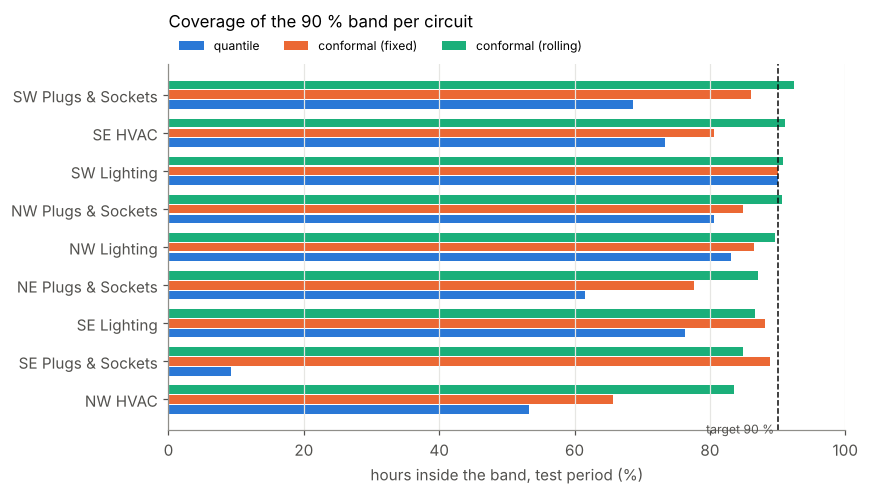

In [5]:
cov = test.pivot(index="circuit", columns="method", values="coverage_%")[METHODS]
cov = cov.loc[cov["conformal (rolling)"].sort_values().index]
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(cov)); h = 0.26
for i, mth in enumerate(METHODS):
    ax.barh(y + (i - 1) * h, cov[mth], height=h - 0.03, color=COL[mth], label=mth)
ax.axvline(90, color="#0b0b0b", lw=1, ls="--"); ax.text(89.5, -0.9, "target 90 %", ha="right", fontsize=8, color="#52514e")
ax.set_yticks(y, cov.index); ax.set_xlim(0, 100); ax.set_xlabel("hours inside the band, test period (%)")
ax.set_title("Coverage of the 90 % band per circuit", loc="left", fontsize=11, pad=24)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0)); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "01_coverage"); plt.show()

**→ Finding (test period, average of the 9 circuits):** coverage 66 % → 83 % → **89 %** for the three versions.
* The raw quantile band is **too narrow**: only 66 % of the hours are inside instead of 90 %.
  SE Plugs is the extreme case (9 %): its use dropped in 2022, so the lower edge learned on older data is too high.
* The fixed conformal widening fixes validation by construction, but on the winter test period it falls short again (83 %),
  because winter does not look like the autumn it was calibrated on.
* The rolling version stays closest to 90 % on test (89 %, 83.5–92.4 % per circuit) **and** on 2025 (89 %), because it keeps
  re-learning how wrong the model has been in the last 4 weeks. The band is a bit wider (0.75 vs 0.62 kWh), but the
  Winkler score, which rewards narrow bands *and* punishes misses, is the best. → **This is the version we keep.**

## 4. What the band looks like: one winter week of NW Plugs & Sockets

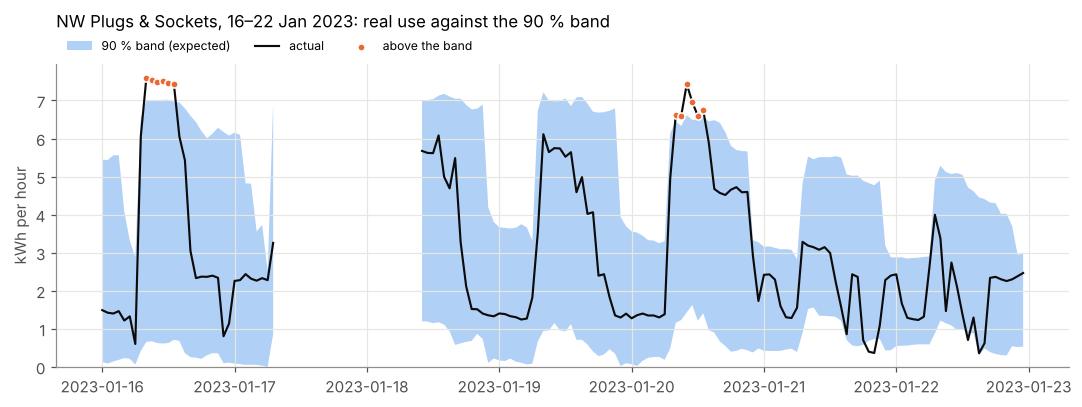

12 of 142 hours with data above the band this week


In [6]:
B = runs["NW|Plugs & Sockets W"]["bands"]["test"].set_index("timestamp_local") / 1000
week = B.loc["2023-01-16":"2023-01-22 23:00"]
week = week.reindex(pd.date_range("2023-01-16", "2023-01-22 23:00", freq="h"))   # missing hours stay empty (no line drawn)
above = week[week["actual"] > week["upper"]]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(week.index, week["lower"], week["upper"], color="#9ec5f4", alpha=0.8, lw=0, label="90 % band (expected)")
ax.plot(week.index, week["actual"], color="#0b0b0b", lw=1.4, label="actual")
ax.scatter(above.index, above["actual"], s=22, color="#eb6834", zorder=3, label="above the band", edgecolor="#fcfcfb", lw=1)
ax.set_ylabel("kWh per hour"); ax.set_ylim(bottom=0)
ax.set_title("NW Plugs & Sockets, 16–22 Jan 2023: real use against the 90 % band", loc="left", fontsize=11, pad=24)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout(); save(fig, "02_week_NW_plugs"); plt.show()
print(f"{len(above)} of {week['actual'].notna().sum()} hours with data above the band this week")

## 5. Out-of-time check: 2025 (Regime B)
Same models, never fitted on 2025. The rolling version needs 7 days of known misses before it starts (warm-up).

In [7]:
b = R.query("period == 'regime_b'")
display(b.groupby("method")[["coverage_%", "above_%", "below_%", "width_kWh", "winkler_kWh"]].mean().reindex(METHODS).round(3))
display(b.pivot(index="circuit", columns="method", values="coverage_%")[METHODS].round(1))

,coverage_%,above_%,below_%,width_kWh,winkler_kWh
method,,,,,
quantile,73.42,8.46,18.12,0.23,0.46
conformal (fixed),86.90,6.54,6.56,0.27,0.44
conformal (rolling),88.71,5.77,5.53,0.27,0.43


method,quantile,conformal (fixed),conformal (rolling)
circuit,,,
NE Plugs & Sockets,78.7,98.6,92.1
NW HVAC,32.8,62.5,90.2
NW Lighting,78.2,85.5,87.9
NW Plugs & Sockets,85.9,95.3,87.7
SE HVAC,96.5,97.6,87.6
SE Lighting,76.8,81.1,80.4
SE Plugs & Sockets,42.0,73.8,93.3
SW Lighting,95.8,95.8,95.8
SW Plugs & Sockets,74.0,91.8,83.3


## 6. Save for the dashboard and the docs
* `reports/interval_results.csv`: every circuit × period × version (all windows).
* `reports/interval_bands.parquet`: hourly band of the kept version (rolling, 28 days) on test and 2025,
  columns `circuit, period, timestamp_local, actual, lower, upper` in W, for the "actual vs expected" chart (KAN-26).

In [8]:
all_rows = pd.concat([r["results"] for r in runs.values()], ignore_index=True)
all_rows.assign(circuit=all_rows["circuit"].map(short)).to_csv(REP / "interval_results.csv", index=False)
bands = pd.concat({(short(c), p): r["bands"][p] for c, r in runs.items() for p in ["test", "regime_b"]},
                  names=["circuit", "period", "row"]).reset_index(level=["circuit", "period"]).reset_index(drop=True)
bands.to_parquet(REP / "interval_bands.parquet", index=False)
print(bands.shape); bands.head()

(14829, 6)


,circuit,period,timestamp_local,actual,lower,upper
0,NW Plugs & Sockets,test,2023-01-01 00:00:00,1319.61,549.59,2524.99
1,NW Plugs & Sockets,test,2023-01-01 01:00:00,1329.44,580.01,2516.82
2,NW Plugs & Sockets,test,2023-01-01 02:00:00,1195.04,561.72,2505.74
3,NW Plugs & Sockets,test,2023-01-01 03:00:00,1412.37,570.41,2508.04
4,NW Plugs & Sockets,test,2023-01-01 04:00:00,1363.74,568.11,2506.95


## 7. Conclusions and limits
* **Kept:** quantile LightGBM (5 % / 95 %) + rolling conformal widening over the last 28 days (chosen on validation).
* **Use in the product:** draw the band in the "actual vs expected" chart; an hour above the band is a first-level warning.
  The event detector of notebook 03 stays the main alert (it needs ≥ 2 h and ≥ 0.5 kWh), the band explains it visually.
* **Limits**
  * Coverage is an *average*: it can be lower at some hours (e.g. winter mornings) and higher at others.
  * The rolling band needs a 7-day warm-up after a gap in the data (seen at the start of 2025).
  * Very low circuits (HVAC, lighting at night) have many hours at almost 0 W, so the coverage there jumps easily.
  * If waste goes on for weeks, the rolling widening slowly gets used to it, so the band becomes wider. The chronic-waste
    rule of notebook 03 covers this case.
* **Next:** add the band to the model card (KAN-162) and to the dashboard data layer (KAN-149 / KAN-26).